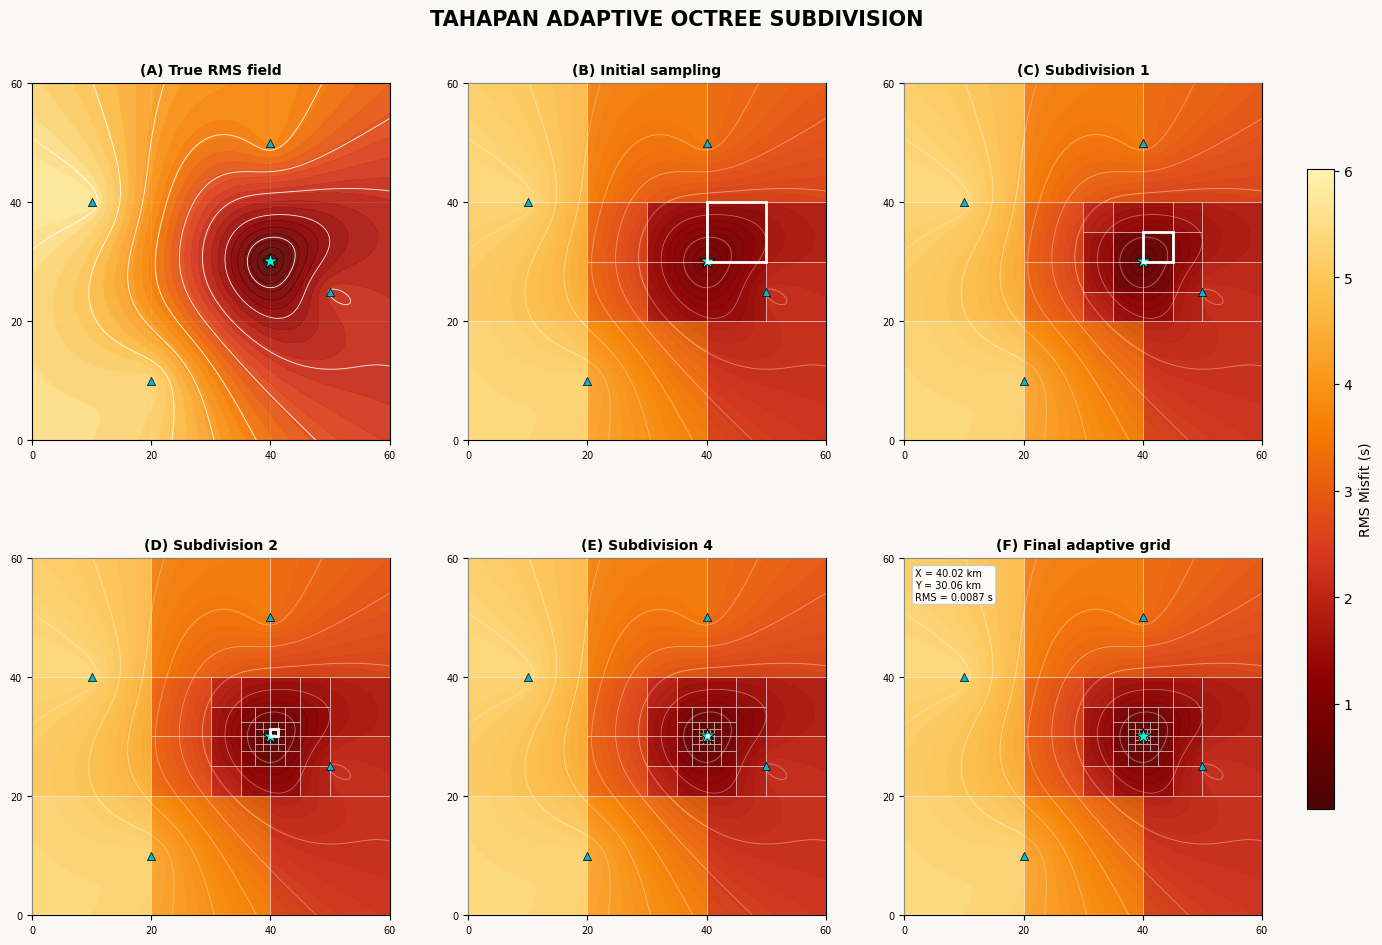

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable

# 1. Data Pengamatan
XS = np.array([20.0, 50.0, 40.0, 10.0])
YS = np.array([10.0, 25.0, 50.0, 40.0])
T_OBS = np.array([7.1, 2.8, 5.0, 7.9])
N_STA = len(XS)
VP = 4.0  # km/s

# 2. Forward Model & Evaluasi RMS
def forward_model(x0, y0, t0, xs, ys, vp):
    distance = np.sqrt((xs - x0)**2 + (ys - y0)**2)
    t_cal = t0 + distance / vp
    return t_cal, distance

def evaluate_candidate(x0, y0):
    _, distance = forward_model(x0, y0, 0.0, XS, YS, VP)
    t0_est = np.mean(T_OBS - distance / VP)
    t_cal, _ = forward_model(x0, y0, t0_est, XS, YS, VP)
    residual = t_cal - T_OBS
    rms = np.sqrt(np.mean(residual**2))
    return rms, t0_est

# 3. Domain & Medan RMS Latar (untuk visualisasi kontur mulus)
X_MIN, X_MAX = 0.0, 60.0
Y_MIN, Y_MAX = 0.0, 60.0
INITIAL_DIVISIONS = 3
MAX_DEPTH = 9
MISFIT_TOL = 0.05

x_vec = np.linspace(X_MIN, X_MAX, 121)
y_vec = np.linspace(Y_MIN, Y_MAX, 121)
XX, YY = np.meshgrid(x_vec, y_vec)

E_RMS_GRID = np.zeros_like(XX)
for row in range(XX.shape[0]):
    for col in range(XX.shape[1]):
        E_RMS_GRID[row, col], _ = evaluate_candidate(XX[row, col], YY[row, col])

GLOBAL_MIN = float(np.min(E_RMS_GRID))

# 4. Fungsi & Proses Adaptive Octree (Quadtree 2D)
def cell_minimum(xmin, xmax, ymin, ymax):
    """Menguji 9 titik dalam sel untuk mendeteksi potensi minimum lokal."""
    xmid = (xmin + xmax) / 2
    ymid = (ymin + ymax) / 2
    best_rms = np.inf
    for x in (xmin, xmid, xmax):
        for y in (ymin, ymid, ymax):
            rms, _ = evaluate_candidate(x, y)
            if rms < best_rms:
                best_rms = rms
    return best_rms

def make_cell(xmin, xmax, ymin, ymax, depth):
    xc = (xmin + xmax) / 2
    yc = (ymin + ymax) / 2
    rms, t0 = evaluate_candidate(xc, yc)
    local_min = cell_minimum(xmin, xmax, ymin, ymax)
    return {
        "xmin": xmin, "xmax": xmax, "ymin": ymin, "ymax": ymax,
        "depth": depth, "x": xc, "y": yc, "rms": rms, "t0": t0,
        "local_min": local_min
    }

def split_cell(cell):
    """Membagi 1 sel menjadi 4 sub-sel."""
    xm = (cell["xmin"] + cell["xmax"]) / 2
    ym = (cell["ymin"] + cell["ymax"]) / 2
    d = cell["depth"] + 1
    return [
        make_cell(cell["xmin"], xm, cell["ymin"], ym, d),
        make_cell(xm, cell["xmax"], cell["ymin"], ym, d),
        make_cell(cell["xmin"], xm, ym, cell["ymax"], d),
        make_cell(xm, cell["xmax"], ym, cell["ymax"], d)
    ]

# Inisialisasi grid awal 3 x 3
x_edges = np.linspace(X_MIN, X_MAX, INITIAL_DIVISIONS + 1)
y_edges = np.linspace(Y_MIN, Y_MAX, INITIAL_DIVISIONS + 1)

leaf_cells = [
    make_cell(x_edges[ix], x_edges[ix + 1], y_edges[iy], y_edges[iy + 1], 0)
    for iy in range(INITIAL_DIVISIONS) for ix in range(INITIAL_DIVISIONS)
]

snapshots = {0: [c.copy() for c in leaf_cells]}

# Subdivisi adaptif
for depth in range(MAX_DEPTH):
    current_best_rms = min(c["local_min"] for c in leaf_cells)
    threshold = current_best_rms + MISFIT_TOL

    new_cells = []
    for cell in leaf_cells:
        if cell["local_min"] <= threshold and cell["depth"] < MAX_DEPTH:
            new_cells.extend(split_cell(cell))
        else:
            new_cells.append(cell)

    leaf_cells = new_cells
    snapshots[depth + 1] = [c.copy() for c in leaf_cells]

best_cell = min(leaf_cells, key=lambda c: c["rms"])
X_EST, Y_EST, T0_EST, E_MIN = best_cell["x"], best_cell["y"], best_cell["t0"], best_cell["rms"]

# 5. Visualisasi Tahapan Octree (6 Panel seperti Gambar 2)
norm = Normalize(vmin=GLOBAL_MIN, vmax=GLOBAL_MIN + 6.0)
cmap = LinearSegmentedColormap.from_list(
    "maroon_to_yellow",
    ["#4A0404", "#8B0000", "#D9381E", "#F77F00", "#FCBF49", "#FFF3B0"]
)

stages = [0, 1, 2, 4, 6, MAX_DEPTH]
stage_titles = [
    "(A) True RMS field",
    "(B) Initial sampling",
    "(C) Subdivision 1",
    "(D) Subdivision 2",
    "(E) Subdivision 4",
    "(F) Final adaptive grid"
]

fig2, axes = plt.subplots(2, 3, figsize=(15, 10), facecolor="#FAF8F5")
axes = axes.ravel()

for k, ax2 in enumerate(axes):
    stage = stages[k]
    ax2.set_facecolor("#FAF8F5")

    # Latar RMS berwarna mulus + garis kontur putih
    ax2.contourf(XX, YY, E_RMS_GRID, levels=35,
                 cmap=cmap, norm=norm, alpha=0.92)
    ax2.contour(XX, YY, E_RMS_GRID,
                levels=np.linspace(GLOBAL_MIN, GLOBAL_MIN + 5.5, 9),
                colors="#FFFFFF", linewidths=0.65, alpha=0.9)

    if k > 0:
        cells_now = snapshots[stage]
        for cell in cells_now:
            face = cmap(norm(cell["rms"]))
            rect = Rectangle(
                (cell["xmin"], cell["ymin"]),
                cell["xmax"] - cell["xmin"], cell["ymax"] - cell["ymin"],
                facecolor=face, edgecolor="#F0F0F0",
                linewidth=0.55, alpha=0.58, zorder=3
            )
            ax2.add_patch(rect)

        # Tandai sel terbaik pada tahap tersebut dengan kotak putih tebal
        stage_best = min(cells_now, key=lambda c: c["rms"])
        best_rect = Rectangle(
            (stage_best["xmin"], stage_best["ymin"]),
            stage_best["xmax"] - stage_best["xmin"], stage_best["ymax"] - stage_best["ymin"],
            fill=False, edgecolor="#FFFFFF", linewidth=2.0, zorder=10
        )
        ax2.add_patch(best_rect)

    # Lokasi stasiun dan hasil estimasi
    ax2.scatter(XS, YS, marker="^", s=35, c="#00B4D8",
                edgecolor="black", linewidth=0.5, zorder=8)
    ax2.scatter(X_EST, Y_EST, marker="*", s=130,
                c="#00F5D4", edgecolor="black", linewidth=0.6, zorder=9)

    ax2.set_xlim(X_MIN, X_MAX)
    ax2.set_ylim(Y_MIN, Y_MAX)
    ax2.set_aspect("equal", adjustable="box")
    ax2.set_xticks([0, 20, 40, 60])
    ax2.set_yticks([0, 20, 40, 60])
    ax2.tick_params(labelsize=7, colors="black")
    ax2.grid(True, linestyle=":", linewidth=0.4, alpha=0.4, color="#FFFFFF")
    ax2.set_title(stage_titles[k], fontsize=10, weight="bold", color="black")

    if k == 5:
        ax2.text(
            0.03, 0.97,
            f"X = {X_EST:.2f} km\nY = {Y_EST:.2f} km\nRMS = {E_MIN:.4f} s",
            transform=ax2.transAxes, va="top", fontsize=7, color="black",
            bbox=dict(boxstyle="round", facecolor="white",
                      edgecolor="#CCCCCC", alpha=0.95)
        )

fig2.suptitle("TAHAPAN ADAPTIVE OCTREE SUBDIVISION", fontsize=15, weight="bold", y=0.98, color="black")
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
fig2.subplots_adjust(left=0.07, right=0.89, bottom=0.07, top=0.91, wspace=0.22, hspace=0.30)
cax = fig2.add_axes([0.92, 0.18, 0.018, 0.64])
cbar2 = fig2.colorbar(sm, cax=cax)
cbar2.set_label("RMS Misfit (s)", color="black")
cbar2.ax.yaxis.set_tick_params(color="black")
plt.setp(cbar2.ax.get_yticklabels(), color="black")
plt.show()